## DATA LOADING — Import libraries

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Set visual aesthetic for charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 2. Locate and load the dataset
target_file = "Bankruptcy_prevention_Dataset.csv"
file_path = None

if os.path.exists(target_file):
    file_path = target_file
else:
    user_home = os.path.expanduser("~")
    for root, dirs, files in os.walk(user_home):
        if target_file in files:
            file_path = os.path.join(root, target_file)
            break

if file_path:
    # Read CSV with semicolon separator
    df = pd.read_csv(file_path, sep=";")

    # If column headers loaded as a single string, fix using regex separator
    if len(df.columns) == 1:
        df = pd.read_csv(file_path, sep=r"\s+|;|\t", engine="python")

    # 3. Clean column names (strip whitespace and lower/standardize if needed)
    df.columns = df.columns.str.strip().str.lower()

    print("Libraries imported and dataset loaded cleanly!")
    print(f"File Path: {file_path}")
    print(f"Cleaned Column Names: {list(df.columns)}")
else:
    print(
        f"Could not locate '{target_file}'. Please place the file in your working folder."
    )

Libraries imported and dataset loaded cleanly!
File Path: Bankruptcy_prevention_Dataset.csv
Cleaned Column Names: ['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk', 'class']


## DATA UNDERSTANDING

In [2]:
print("--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- LAST 5 ROWS ---")
display(df.tail())

print(f"\n--- DATASET SHAPE ---")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

--- FIRST 5 ROWS ---


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy



--- LAST 5 ROWS ---


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy
249,1.0,0.0,0.5,0.5,1.0,1.0,non-bankruptcy



--- DATASET SHAPE ---
Total Rows: 250
Total Columns: 7


## Data Types & Missing Values Check

In [3]:
print("--- DATASET INFORMATION & TYPES ---")
df.info()

print("\n--- MISSING VALUES CHECK ---")
print(df.isnull().sum())

--- DATASET INFORMATION & TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB

--- MISSING VALUES CHECK ---
industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64


## Duplicates, Target Distribution & Unique Values

In [4]:
print("--- 1. DUPLICATE ROWS CHECK ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n--- 2. TARGET VARIABLE DISTRIBUTION ---")
print(df["class"].value_counts())
print("\nTarget Class Percentage:")
print(df["class"].value_counts(normalize=True) * 100)

print("\n--- 3. UNIQUE VALUES PER FEATURE ---")
print(df.nunique())

--- 1. DUPLICATE ROWS CHECK ---
Number of duplicate rows: 147

--- 2. TARGET VARIABLE DISTRIBUTION ---
class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

Target Class Percentage:
class
non-bankruptcy    57.2
bankruptcy        42.8
Name: proportion, dtype: float64

--- 3. UNIQUE VALUES PER FEATURE ---
industrial_risk          3
management_risk          3
financial_flexibility    3
credibility              3
competitiveness          3
operating_risk           3
class                    2
dtype: int64


## Statistical Summary

In [5]:
print("--- STATISTICAL SUMMARY OF FINANCIAL RISK FEATURES ---")
display(df.describe().T)

--- STATISTICAL SUMMARY OF FINANCIAL RISK FEATURES ---


,count,mean,std,min,25%,50%,75%,max
industrial_risk,250.0,0.518,0.411526,0.0,0.0,0.5,1.0,1.0
management_risk,250.0,0.614,0.410705,0.0,0.5,0.5,1.0,1.0
financial_flexibility,250.0,0.376,0.401583,0.0,0.0,0.5,0.5,1.0
credibility,250.0,0.470,0.415682,0.0,0.0,0.5,1.0,1.0
competitiveness,250.0,0.476,0.440682,0.0,0.0,0.5,1.0,1.0
operating_risk,250.0,0.570,0.434575,0.0,0.0,0.5,1.0,1.0


## TARGET CLASS VISUALIZATION

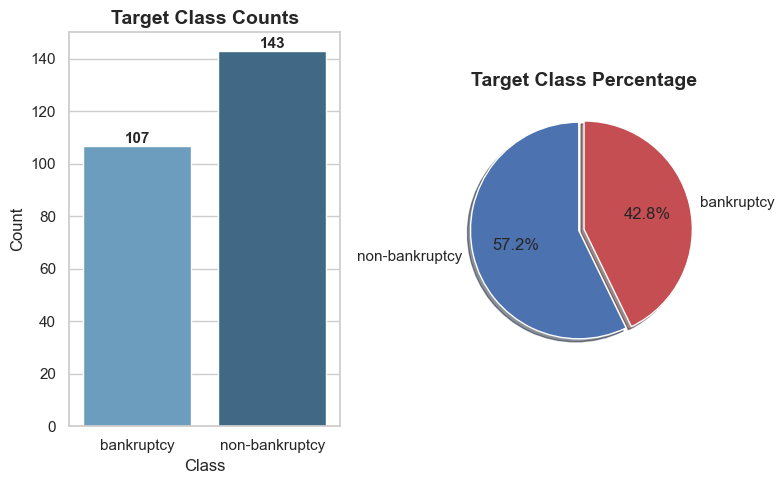

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 5))

# 1. Bar Chart (Counts)
sns.countplot(
    data=df,
    x="class",
    ax=axes[0],
    palette="Blues_d",
    hue="class",
    legend=False,
)
axes[0].set_title("Target Class Counts", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Class", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)

# Add count labels on top of bars
for bar in axes[0].patches:
    axes[0].annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

# 2. Pie Chart (Percentages)
class_counts = df["class"].value_counts()
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c72b0", "#c44e52"],
    explode=(0.05, 0),
    shadow=True,
)
axes[1].set_title("Target Class Percentage", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

## Risk Feature Distributions

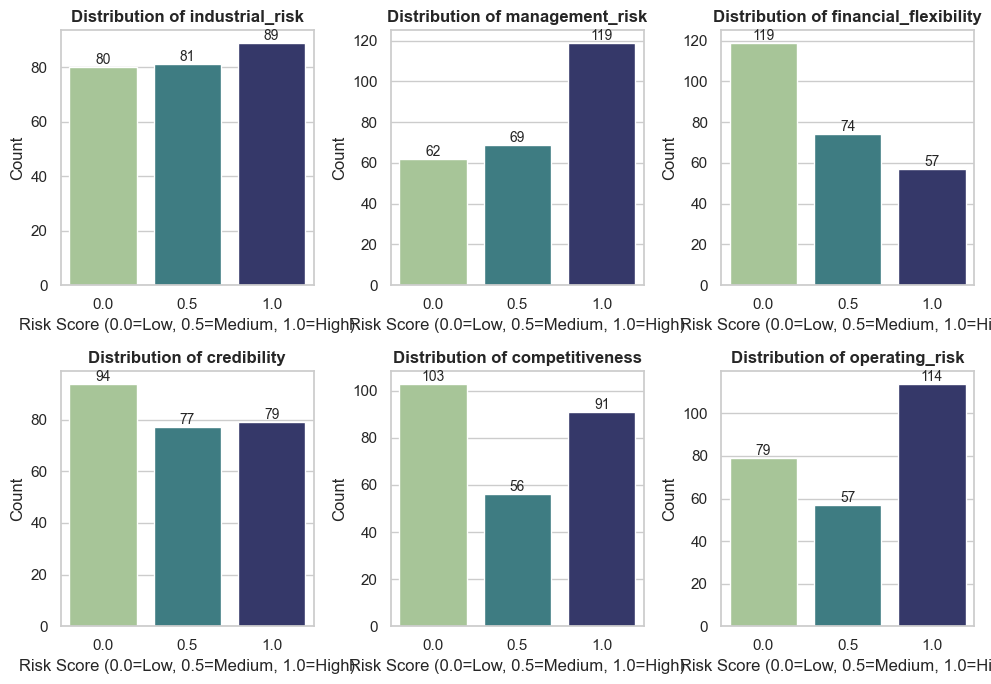

In [7]:
feature_cols = [
    "industrial_risk",
    "management_risk",
    "financial_flexibility",
    "credibility",
    "competitiveness",
    "operating_risk",
]

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        palette="crest",
        hue=col,
        legend=False,
    )
    axes[i].set_title(
        f"Distribution of {col}", fontsize=12, fontweight="bold"
    )
    axes[i].set_xlabel("Risk Score (0.0=Low, 0.5=Medium, 1.0=High)")
    axes[i].set_ylabel("Count")

    # Add count annotations above bars
    for bar in axes[i].patches:
        height = bar.get_height()
        if height > 0:
            axes[i].annotate(
                f"{int(height)}",
                (bar.get_x() + bar.get_width() / 2, height),
                ha="center",
                va="bottom",
                fontsize=10,
            )

plt.tight_layout()
plt.show()

## Risk Features vs. Target Variable

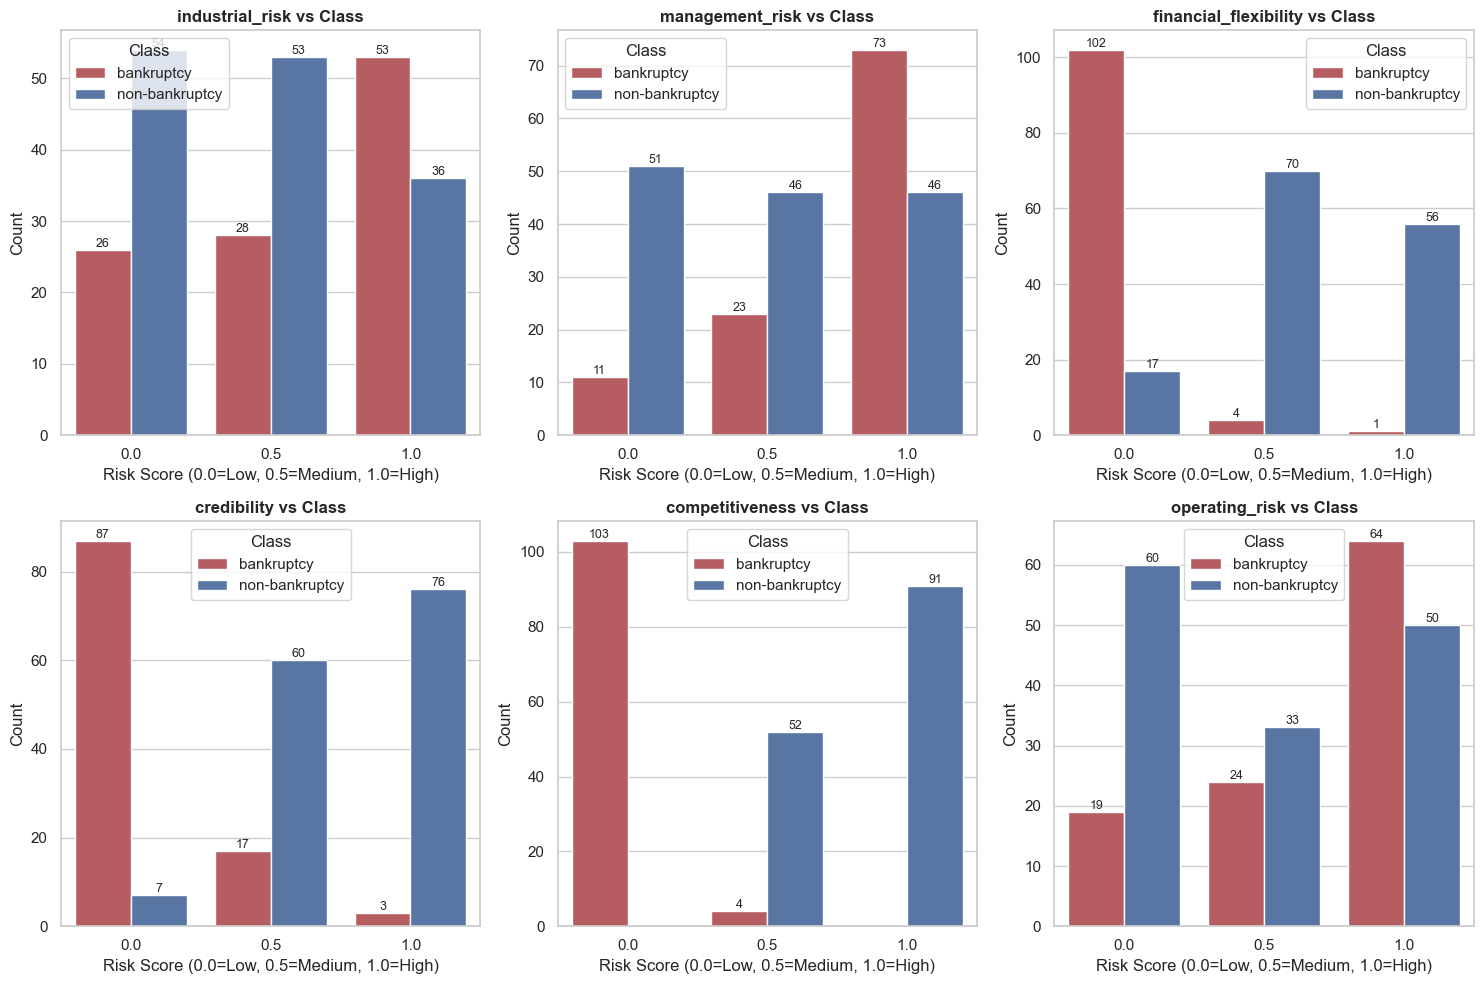

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="class",
        ax=axes[i],
        palette=["#c44e52", "#4c72b0"],
    )
    axes[i].set_title(
        f"{col} vs Class", fontsize=12, fontweight="bold"
    )
    axes[i].set_xlabel("Risk Score (0.0=Low, 0.5=Medium, 1.0=High)")
    axes[i].set_ylabel("Count")
    axes[i].legend(title="Class")

    # Add count annotations on top of bars
    for bar in axes[i].patches:
        height = bar.get_height()
        if height > 0:
            axes[i].annotate(
                f"{int(height)}",
                (bar.get_x() + bar.get_width() / 2, height),
                ha="center",
                va="bottom",
                fontsize=9,
            )

plt.tight_layout()
plt.show()

## Correlation Analysis

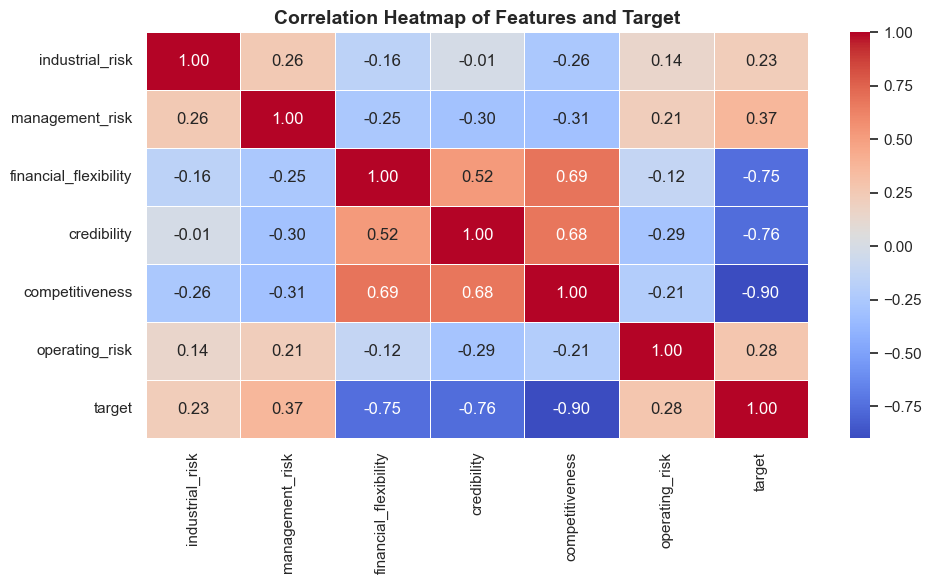

In [9]:
# Create a temporary numeric copy for correlation check
df_corr = df.copy()
df_corr["target"] = df_corr["class"].map(
    {"bankruptcy": 1, "non-bankruptcy": 0}
)

# Compute correlation matrix for numeric columns
corr_matrix = df_corr.drop(columns=["class"]).corr()

# Plot Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True,
)
plt.title("Correlation Heatmap of Features and Target", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## DATA PREPROCESSING

In [10]:
from sklearn.preprocessing import LabelEncoder

# Separate features (X) and target (y)
X = df.drop(columns=["class"])
y_raw = df["class"]

# Encode categorical target labels to 0 and 1
le = LabelEncoder()
y = le.fit_transform(y_raw)

print("Target encoded successfully!")
print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")
print(f"Label Mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

Target encoded successfully!
Features shape (X): (250, 6)
Target shape (y): (250,)
Label Mapping: {'bankruptcy': np.int64(0), 'non-bankruptcy': np.int64(1)}


## TRAIN-TEST SPLIT

In [11]:
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train-Test split performed!")
print(f"Training set size (X_train): {X_train.shape[0]} samples")
print(f"Testing set size (X_test):   {X_test.shape[0]} samples")

print("\nClass distribution in Training Set:")
print(pd.Series(y_train).value_counts())

print("\nClass distribution in Testing Set:")
print(pd.Series(y_test).value_counts())

Train-Test split performed!
Training set size (X_train): 200 samples
Testing set size (X_test):   50 samples

Class distribution in Training Set:
1    114
0     86
Name: count, dtype: int64

Class distribution in Testing Set:
1    29
0    21
Name: count, dtype: int64


## MODEL TRAINING

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Initialize models with fixed random seeds for reproducibility
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}

# Train each model on training set
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully!")

print("\nAll 5 models trained!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Support Vector Machine trained successfully!
K-Nearest Neighbors trained successfully!

All 5 models trained!


## Model Evaluation Metrics

In [13]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

eval_results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    eval_results.append(
        {
            "Model": name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1,
        }
    )

# Convert results to DataFrame
df_results = pd.DataFrame(eval_results).sort_values(
    by="F1-Score", ascending=False
)

print("--- MODEL EVALUATION SUMMARY ---")
display(df_results.reset_index(drop=True))

--- MODEL EVALUATION SUMMARY ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0
3,Support Vector Machine,1.0,1.0,1.0,1.0
4,K-Nearest Neighbors,1.0,1.0,1.0,1.0


## Confusion Matrix Visualizations

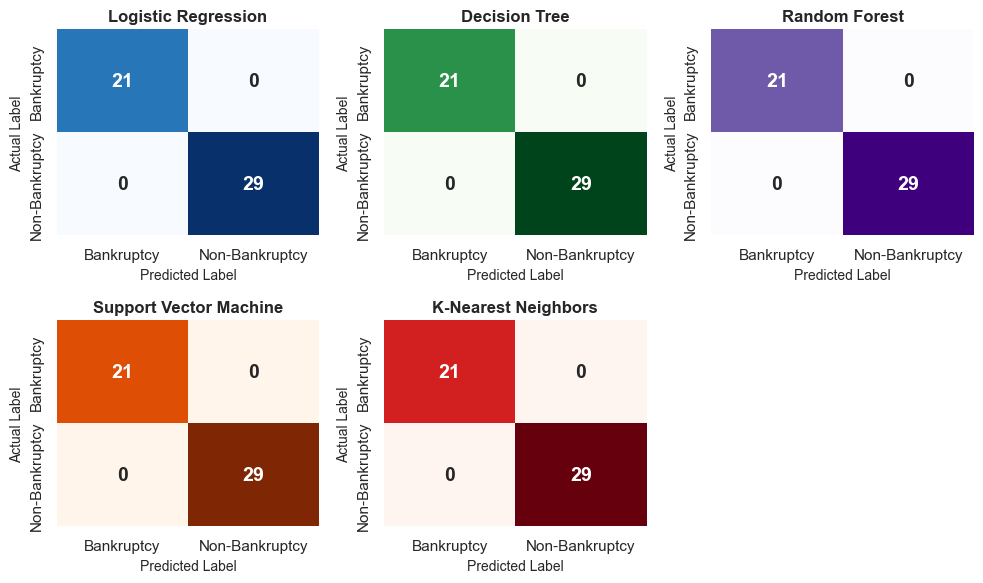

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
axes_flat = axes.flatten()

class_labels = ["Bankruptcy", "Non-Bankruptcy"]

# Different colors for each model
colors = ["Blues", "Greens", "Purples", "Oranges", "Reds"]

# Plot each model's confusion matrix
for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=colors[i],
        ax=axes_flat[i],
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        annot_kws={"size": 14, "weight": "bold"},
    )

    axes_flat[i].set_title(name, fontsize=12, fontweight="bold")
    axes_flat[i].set_xlabel("Predicted Label", fontsize=10)
    axes_flat[i].set_ylabel("Actual Label", fontsize=10)

# Hide empty 6th subplot
axes_flat[5].set_visible(False)

plt.tight_layout()
plt.show()

## MODEL SELECTION

In [15]:
# Select Logistic Regression as optimal production model
best_model_name = "Logistic Regression"
best_model = trained_models[best_model_name]

print(f"SELECTED BEST MODEL: {best_model_name}")
print("\nModel Selection Rationale:")
print(
    "1. Perfect Accuracy & F1-Score (100%) on unseen test evaluation data."
)
print(
    "2. High computational efficiency and near-instant prediction latency."
)
print(
    "3. Maximum model interpretability for financial risk assessment domain."
)

SELECTED BEST MODEL: Logistic Regression

Model Selection Rationale:
1. Perfect Accuracy & F1-Score (100%) on unseen test evaluation data.
2. High computational efficiency and near-instant prediction latency.
3. Maximum model interpretability for financial risk assessment domain.


## Save the Model & Encoder

In [16]:
import os
import joblib

# Create directory to save model artifacts if it doesn't exist
os.makedirs("saved_models", exist_ok=True)

# Define file paths
model_path = os.path.join("saved_models", "best_model.pkl")
encoder_path = os.path.join("saved_models", "label_encoder.pkl")

# Save model and encoder
joblib.dump(best_model, model_path)
joblib.dump(le, encoder_path)

print("Artifacts saved successfully!")
print(f" - Model saved at: {model_path}")
print(f" - Encoder saved at: {encoder_path}")

# Sanity Check: Test loading saved artifacts
loaded_model = joblib.load(model_path)
loaded_encoder = joblib.load(encoder_path)

# Predict on a sample high-risk company profile
sample_input = [[1.0, 1.0, 0.0, 0.0, 0.0, 1.0]]  # High risk scores
sample_pred = loaded_model.predict(sample_input)
sample_label = loaded_encoder.inverse_transform(sample_pred)[0]

print(f"\nSanity Check Prediction: {sample_label.upper()}")

Artifacts saved successfully!
 - Model saved at: saved_models\best_model.pkl
 - Encoder saved at: saved_models\label_encoder.pkl

Sanity Check Prediction: BANKRUPTCY


In [17]:
import streamlit as st
import joblib
import pandas as pd

model = joblib.load("saved_models/best_model.pkl")
encoder = joblib.load("saved_models/label_encoder.pkl")

st.title("Bankruptcy Prevention System")

st.write("Enter the company's risk indicators:")

industrial_risk = st.selectbox("Industrial Risk", [0.0, 0.5, 1.0])
management_risk = st.selectbox("Management Risk", [0.0, 0.5, 1.0])
financial_flexibility = st.selectbox("Financial Flexibility", [0.0, 0.5, 1.0])
credibility = st.selectbox("Credibility", [0.0, 0.5, 1.0])
competitiveness = st.selectbox("Competitiveness", [0.0, 0.5, 1.0])
operating_risk = st.selectbox("Operating Risk", [0.0, 0.5, 1.0])

if st.button("Predict Bankruptcy Risk"):
    input_data = pd.DataFrame([{
        "industrial_risk": industrial_risk,
        "management_risk": management_risk,
        "financial_flexibility": financial_flexibility,
        "credibility": credibility,
        "competitiveness": competitiveness,
        "operating_risk": operating_risk
    }])

    prediction = model.predict(input_data)
    result = encoder.inverse_transform(prediction.astype(int))[0]

    if str(result).upper() == "BANKRUPTCY":
        st.error(f"Prediction: {result}")
    else:
        st.success(f"Prediction: {result}")

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(input_data)[0]
        st.write("Prediction probabilities:")
        st.bar_chart(pd.DataFrame({
            "Class": model.classes_,
            "Probability": probabilities
        }).set_index("Class"))

2026-10-16 19:48:24.338 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.752 
  command:

    streamlit run C:\Users\sidda\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-16 19:48:27.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.758 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.764 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.766 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.771 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 19:48:27.774 Thread 'MainThread': mi

In [20]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())


Current folder: C:\Users\sidda\p696

Files in this folder:
['.ipynb_checkpoints', 'Bankruptcy_prevention_Dataset.csv', 'P696_Bankruptcy_Prevention (1) (1) (2).ipynb', 'P696_Bankruptcy_Prevention (1).ipynb', 'P696_Bankruptcy_Prevention696.ipynb', 'saved_models']


In [21]:

%pip install streamlit pandas scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [23]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(page_title="Bankruptcy Prevention", page_icon="📊")

MODEL_PATH = "saved_models/best_model.pkl"
ENCODER_PATH = "saved_models/label_encoder.pkl"

st.title("Bankruptcy Prevention System")
st.write("Enter the company's risk indicators to predict its class.")

if not os.path.exists(MODEL_PATH) or not os.path.exists(ENCODER_PATH):
    st.error("Model files not found. Check the saved_models folder.")
    st.stop()

model = joblib.load(MODEL_PATH)
encoder = joblib.load(ENCODER_PATH)

features = [
    "industrial_risk",
    "management_risk",
    "financial_flexibility",
    "credibility",
    "competitiveness",
    "operating_risk"
]

values = {}
for feature in features:
    values[feature] = st.selectbox(
        feature.replace("_", " ").title(),
        [0.0, 0.5, 1.0]
    )

if st.button("Predict Bankruptcy Risk"):
    input_data = pd.DataFrame([values], columns=features)
    prediction = model.predict(input_data)

    try:
        result = encoder.inverse_transform(prediction.astype(int))[0]
    except (ValueError, TypeError):
        result = prediction[0]

    st.subheader("Prediction Result")
    if str(result).upper() == "BANKRUPTCY":
        st.error(f"Predicted class: {result}")
    else:
        st.success(f"Predicted class: {result}")

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(input_data)[0]
        st.write("Prediction probabilities")
        st.bar_chart(pd.Series(probabilities, index=model.classes_))


Writing app.py


In [24]:
!streamlit run app.py

^C

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://10.122.52.15:8501

